In [25]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
file2=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test_new/CH_results/NIWG_ehouarn_ch.root")
# file3=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test2/workdir/test/test_inclusive.root")
file3=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test_new/CH_results/jg_final_CH.root")

mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate


incident_counter_w_med=file3['Events;1']['incident'].array()
px_gibuu_w_med=file3['Events;1']['momX'].array()
py_gibuu_w_med=file3['Events;1']['momY'].array()
pz_gibuu_w_med=file3['Events;1']['momZ'].array()
E_gibuu_w_med=file3['Events;1']['momE'].array()
ID_gibuu_w_med=file3['Events;1']['ID'].array()
charge_gibuu_w_med=file3['Events;1']['Charge'].array()
history_gibuu_w_med=file3['Events;1']['history'].array()
prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
incident_counter_gibuu_w_med1=ak.Array([incident_counter_w_med[i] for i in range(len(incident_counter_w_med)) if len(prodid_gibuu_w_med[i])>2])

In [11]:
chase, isatPV

(<Array [[0, 0, 0, 0, 0], ..., [0, 0, ..., 1, 1]] type='1000000 * var * int32'>,
 <Array [[True, True, True, True, True], ..., [...]] type='1000000 * var * bool'>)

In [26]:
idx=np.arange(0,1000000,1)
mask_chase= (targetA==12)
mask_chase1=((ak.sum(chase,axis=1))==ak.sum(chase[isatPV],axis=1))&(ak.sum(chase,axis=1)==0)
idx=idx[(mask_chase) & (~mask_chase1)]
print(idx,len(idx))

[     1      2      3 ... 999997 999998 999999] 959183


In [30]:
chase[mask_chase1]

<Array [[0, 0, 0, 0, 0], [...], ..., [0, 0, 0, 0, 0]] type='8147 * var * int32'>

In [31]:
np.unique(weight)

<Array [6.24e-45] type='1 * float64'>

In [27]:
idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
# idx=incident_counter_gibuu_wo_med1[idx]
idx2=incident_counter_w_med[idx2]

# _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
_, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)

In [33]:
np.sum(targetA==1)

np.int64(32670)

In [34]:
px[idx1][6],px_gibuu_w_med[idx2][6]

(<Array [0, -0.191, -0.0206, 0.108, -0.279, -0.272] type='6 * float64'>,
 <Array [-0.0206, -0.191, 0.287, 0.11, -0.667] type='5 * float64'>)

In [28]:
import pandas as pd
import numpy as np
from scipy.interpolate import make_interp_spline
file=pd.read_csv("Pion_xsec.dat")
### data table read for reweighting events with Delta cross-section 
def read():
    z=[]
    for lines in file["# 1pi :Graczyk & Sobczyk default :MA=0.95"]:
        x=lines.split()
        y=[int(x[0]),int(x[1]), float(x[2]),float(x[3]),float(x[4]),float(x[5])]
        z.append(y)
    return np.array(z)
read()

array([[ 1.40000e+01,  1.00000e+00,  1.50000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       [ 1.40000e+01,  1.00000e+00,  2.00000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       [ 1.40000e+01,  1.00000e+00,  2.50000e-01, -0.00000e+00,
        -0.00000e+00, -0.00000e+00],
       ...,
       [ 1.40000e+01,  2.00000e+00,  6.00000e+02,  7.36338e+00,
         1.63726e+00,  8.19062e-01],
       [ 1.40000e+01,  2.00000e+00,  8.00000e+02,  7.36329e+00,
         1.63904e+00,  8.20760e-01],
       [ 1.40000e+01,  2.00000e+00,  1.00000e+03,  7.36326e+00,
         1.64071e+00,  8.22473e-01]], shape=(196, 6))

Text(0, 0.5, 'Xsec_$\\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)')

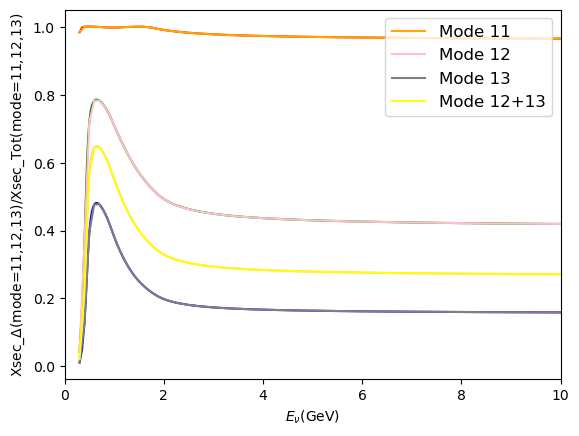

In [29]:
#### splines prepared for event reweighting with arbitrary neutrino energy
import matplotlib.pyplot as plt
results=np.array(read())
modex=results[:,1]
neutrinox=results[:,0]
enx=results[:,2]
mode11x=results[:,3]
mode12x=results[:,4]
mode13x=results[:,5]

tot11=mode11x[(modex==1)]
tot12=mode12x[(modex==1)]
tot13=mode13x[(modex==1)]

tot11delta=mode11x[(modex==2)]
tot12delta=mode12x[(modex==2)]
tot13delta=mode13x[(modex==2)]



enx=enx[modex==1]

plt.plot(enx[3:],tot11delta[3:]/tot11[3:], "red")
plt.plot(enx[3:],tot12delta[3:]/tot12[3:],"green")
plt.plot(enx[3:],tot13delta[3:]/tot13[3:], "blue")
plt.plot(enx[3:],(tot13delta[3:]+tot12delta[3:])/(tot12[3:]+tot13[3:]), color="pink")
bspl1 = make_interp_spline(enx[3:],tot11delta[3:]/tot11[3:])
bspl2 = make_interp_spline(enx[3:],tot12delta[3:]/tot12[3:])
bspl3 = make_interp_spline(enx[3:],tot13delta[3:]/tot13[3:])
bspl4 = make_interp_spline(enx[3:],(tot13delta[3:]+tot12delta[3:])/(tot12[3:]+tot13[3:]))

xx = np.linspace(0.3, 10, 100)

plt.plot(xx,bspl1(xx), "orange", label="Mode 11")
plt.plot(xx,bspl2(xx), "pink",label="Mode 12")
plt.plot(xx,bspl3(xx), "gray",label="Mode 13")
plt.plot(xx,bspl4(xx), "yellow",label="Mode 12+13")
plt.legend(fontsize=12)
enx[2:]
plt.xlim(0,10)
plt.xlabel(r"$E_{\nu}$(GeV)")
plt.ylabel(r"Xsec_$\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)")

In [30]:
## CC1pi+ (for Q^2 and theta_mu,pi cross-sections) selection for NEUT and GIBUU

def cc0pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,binding):
    pi_mom_cut=0.2
    pi_th_cut=0.2
    p_mom_cutl=0.45
    p_mom_cutu=1.0
    th_mom_cut=0.4
    p_lep_mom_cut=0.250
    theta_lep_cut=-0.6
    final_state=chase_arr==1
    theta_mom=np.arccos(pz_arr/np.sqrt(px_arr**2+py_arr**2+pz_arr**2))
    p_mom=np.sqrt(px_arr**2+py_arr**2+pz_arr**2)
    
    # pion definitions
    is_pi_plus  = (pdg_arr == 211) & (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)
    is_pi_minus = (pdg_arr == -211)& (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)
    is_pi0      = (pdg_arr == 111) & (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)
    is_proton = (pdg_arr == 2212)  & (p_mom>=p_mom_cutl) & (p_mom<=p_mom_cutu) & (np.cos(theta_mom)>th_mom_cut) & (E_arr-binding-0.938 > 0)
    is_accepteable_lepton=(pdg_arr == 13) & (p_mom>p_lep_mom_cut) & (np.cos(theta_mom)>theta_lep_cut)
    is_meson = (np.abs(pdg_arr) >= 100) & (np.abs(pdg_arr) < 1000) #& (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)   # all PDG mesons: π, K, η, ρ, ...

    # counts per event
    n_pi_plus  = ak.sum(is_pi_plus & final_state, axis=1)
    n_pi_minus = ak.sum(is_pi_minus & final_state, axis=1)
    n_pi0      = ak.sum(is_pi0 & final_state, axis=1)
    n_proton = ak.sum(is_proton & final_state, axis=1)
    n_lepton= ak.sum(is_accepteable_lepton & final_state, axis=1)
    n_meson  = ak.sum(is_meson & final_state, axis=1)
    mask_cc0pi = (n_meson == 0) & (n_proton > 0) & (n_lepton > 0)    
    # CC1pi+ mask 
    # mask_cc0pi = (n_pi_plus == 0) & (n_pi_minus == 0) & (n_pi0 == 0) & (n_proton >0) & (n_lepton>0)
    mask_cc0pi_pi= is_pi_plus[mask_cc0pi] & final_state[mask_cc0pi]
    mask_cc0pi_mu= is_accepteable_lepton[mask_cc0pi] & final_state[mask_cc0pi]
    mask_cc0pi_proton= is_proton[mask_cc0pi] & final_state[mask_cc0pi]
    
    return mask_cc0pi, mask_cc0pi_pi, mask_cc0pi_mu, mask_cc0pi_proton

def cc0pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr3,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,binding,px_arr3l,py_arr3l,pz_arr3l,E_arr3l):
    pi_mom_cut=0.2
    pi_th_cut=0.2
    p_mom_cutl=0.45
    p_mom_cutu=1.0
    th_mom_cut=0.4
    p_lep_mom_cut=0.250
    theta_lep_cut=-0.6

    theta_mom=np.arccos(pz_arr3/np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2))
    p_mom=np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
    p_lep_mom= np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2)
    theta_lep= np.arccos(pz_arr3l/np.sqrt(px_arr3l**2+py_arr3l**2+pz_arr3l**2))   
    # final state
    final_state_w_gibuu = (pdg_arr3 == 101)
    
    # pion definitions
    is_pi_plus_w_gibuu  = (charge_arr3 == 1) & (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)
    is_pi_minus_w_gibuu = (charge_arr3 == -1) & (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)
    is_pi0_w_gibuu      = (charge_arr3 == 0)  & (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)
    is_proton_w_gibuu = (charge_arr3 == 1) & (pdg_arr3 == 1) & (E_arr3-binding-0.938 > 0) & (p_mom>=p_mom_cutl) & (p_mom<=p_mom_cutu) & (np.cos(theta_mom)>th_mom_cut)              
    is_acceptable_w_lepton= (p_lep_mom>p_lep_mom_cut) & (np.cos(theta_lep)>theta_lep_cut)
    is_meson_gibuu   = (np.abs(pdg_arr3) >= 100) & (np.abs(pdg_arr3) < 200)  #& (p_mom>pi_mom_cut) & (theta_mom>pi_th_cut)   
    # counts per event
    n_pi_plus_w_gibuu  = ak.sum(is_pi_plus_w_gibuu & final_state_w_gibuu, axis=1)
    n_pi_minus_w_gibuu = ak.sum(is_pi_minus_w_gibuu & final_state_w_gibuu, axis=1)
    n_pi0_w_gibuu      = ak.sum((is_pi0_w_gibuu & final_state_w_gibuu), axis=1)
    n_proton_w_gibuu     = ak.sum((is_proton_w_gibuu), axis=1)
    n_meson_w_gibuu  = ak.sum(is_meson_gibuu, axis=1)
    mask_cc0pi_w_gibuu = (n_meson_w_gibuu == 0) & (n_proton_w_gibuu > 0) & (is_acceptable_w_lepton==True)   
    # CC1pi+ mask 
    # mask_cc0pi_w_gibuu = (n_pi_plus_w_gibuu == 0) & (n_pi_minus_w_gibuu == 0) & (n_pi0_w_gibuu == 0) & (n_proton_w_gibuu>0) & (is_acceptable_w_lepton==True)
    # select only CC1pi+ events
    mask_cc0pi_pi_w_gibuu= is_pi_plus_w_gibuu[mask_cc0pi_w_gibuu] & final_state_w_gibuu[mask_cc0pi_w_gibuu]
    mask_cc0pi_proton_w_gibuu= is_proton_w_gibuu[mask_cc0pi_w_gibuu] 
    
    return mask_cc0pi_w_gibuu, mask_cc0pi_pi_w_gibuu, mask_cc0pi_w_gibuu, mask_cc0pi_proton_w_gibuu

def to3( px, py, pz):
    def _np(a):
        return np.asarray(ak.to_numpy(ak.fill_none(a, np.nan)), dtype=float)
    return np.stack([_np(px), _np(py), _np(pz)], axis=1)    

In [31]:
## reconstructed variables definitions
import numpy as np
import numba as nb
from numba import njit, prange

nb.set_num_threads(4)

@njit(parallel=True, fastmath=True, cache=True)
def _kernel(px_mu, py_mu, pz_mu,
            m_p, m_n, m_mu, m_pi, B, E_nu_rec, Q2_rec):
    for i in prange(px_mu.shape[0]):
        E_mu = np.sqrt(px_mu[i]**2 + py_mu[i]**2 + pz_mu[i]**2 + m_mu**2)
        # # E_pi = np.sqrt(px_pi[i]**2 + py_pi[i]**2 + pz_pi[i]**2 + m_pi**2)
        costh_mu=np.arccos(pz_mu[i]/(np.sqrt(px_mu[i]**2 + py_mu[i]**2 + pz_mu[i]**2)))
        p_mu=np.sqrt(px_mu[i]**2 + py_mu[i]**2 + pz_mu[i]**2)
        # px = px_mu[i] #+ px_pi[i]
        # py = py_mu[i] #+ py_pi[i]
        # pz = pz_mu[i] #+ pz_pi[i]
        # pvis2 = px*px + py*py + pz*pz

        A = m_n - B - E_mu +p_mu*costh_mu
        E = (m_p**2 - (m_n-B)**2-m_mu**2+2*(m_n-B)*E_mu) / (2.0 * (A))

        E_nu_rec[i] = E
        Q2_rec[i] = 2.0 * E * (E_mu - pz_mu[i]*costh_mu) - m_mu**2
        # Q2_rec[i] = -(m_mu**2-2*E*(E_mu-p_mu*costh_mu))

def t2k_cc0pip_reco(px_mu, py_mu, pz_mu,
                    m_p=0.9382720813, m_n=0.93957, m_mu=0.1056583755,
                    m_pi=0.13957039, binding_energy=0.025):
    # constants must be true scalars
    for name, v in dict(m_p=m_p, m_mu=m_mu, m_pi=m_pi,
                        binding_energy=binding_energy).items():
        if np.ndim(v) != 0:
            raise ValueError(f"{name} must be a scalar, got shape {np.shape(v)}")

    arrs = np.broadcast_arrays(*[np.asarray(a, dtype=np.float64)
                                 for a in (px_mu, py_mu, pz_mu)])
    shape = arrs[0].shape
    flat = [np.ascontiguousarray(a).ravel() for a in arrs]   # all 1D now

    E_nu_rec = np.empty(flat[0].shape, dtype=np.float64)
    Q2_rec = np.empty(flat[0].shape, dtype=np.float64)

    _kernel(*flat, float(m_p), float(m_n),float(m_mu), float(m_pi),float(binding_energy),
            E_nu_rec, Q2_rec)
    return E_nu_rec.reshape(shape), Q2_rec.reshape(shape)

def t2k_cc0pip_reco_gibuu(px_mu, py_mu, pz_mu,
                    m_p=0.9382720813,m_n=0.93957, m_mu=0.1056583755,
                    m_pi=0.13957039, binding_energy=0.0):
    # constants must be true scalars
    for name, v in dict(m_p=m_p, m_mu=m_mu, m_pi=m_pi,
                        binding_energy=binding_energy).items():
        if np.ndim(v) != 0:
            raise ValueError(f"{name} must be a scalar, got shape {np.shape(v)}")

    arrs = np.broadcast_arrays(*[np.asarray(a, dtype=np.float64)
                                 for a in (px_mu, py_mu, pz_mu)])
    shape = arrs[0].shape
    flat = [np.ascontiguousarray(a).ravel() for a in arrs]   # all 1D now

    E_nu_rec = np.empty(flat[0].shape, dtype=np.float64)
    Q2_rec = np.empty(flat[0].shape, dtype=np.float64)

    _kernel(*flat, float(m_p),float(m_n), float(m_mu), float(m_pi), float(binding_energy),
            E_nu_rec, Q2_rec)
    return E_nu_rec.reshape(shape), Q2_rec.reshape(shape)

In [32]:
## event selection for NEUT
## CC1PI event selection
pdg_arr   = pdg[idx1]
mode_arr = mode[idx1]
chase_arr = chase[idx1]
E_arr     = E[idx1]
Q2_arr = Q2[idx1]
px_arr = px[idx1]
py_arr= py[idx1]
pz_arr=pz[idx1]
mass_offset=0.025
# proton selection (final state)
mask_cc0pi_all=cc0pi_masks(mode_arr,pdg_arr,Q2_arr,chase_arr,px_arr,py_arr,pz_arr,E_arr,mass_offset)


ppi_for_reco=to3(px_arr[mask_cc0pi_all[0]][mask_cc0pi_all[1]],py_arr[mask_cc0pi_all[0]][mask_cc0pi_all[1]],pz_arr[mask_cc0pi_all[0]][mask_cc0pi_all[1]])
pmu_for_reco=to3(px_arr[mask_cc0pi_all[0]][mask_cc0pi_all[2]],py_arr[mask_cc0pi_all[0]][mask_cc0pi_all[2]],pz_arr[mask_cc0pi_all[0]][mask_cc0pi_all[2]])
beam_dir = np.tile(np.array([0., 0., 1.]), (len(ppi_for_reco), 1))

In [33]:
px_mu=np.array(ak.flatten(pmu_for_reco[:,0]))
py_mu=np.array(ak.flatten(pmu_for_reco[:,1]))
pz_mu=np.array(ak.flatten(pmu_for_reco[:,2]))

output=t2k_cc0pip_reco(px_mu, py_mu, pz_mu)

In [41]:
pz_mu

array([ 0.35392575,  0.85826947, -0.08985899, ...,  0.18934389,
        0.5868894 ,  1.02150201], shape=(279255,))

In [34]:
## GiBUU events
pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
px_arr3 = px_gibuu_w_med[idx2][:,2:]
py_arr3 = py_gibuu_w_med[idx2][:,2:]
pz_arr3 = pz_gibuu_w_med[idx2][:,2:]
E_arr3   = E_gibuu_w_med[idx2][:,2:]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
px_arr3l = px_gibuu_w_med[idx2][:,0]
py_arr3l = py_gibuu_w_med[idx2][:,0]
pz_arr3l = pz_gibuu_w_med[idx2][:,0]
E_arr3l   = E_gibuu_w_med[idx2][:,0] 
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
mass_offset=0.0
mask_cc0pi_all_gibuu=cc0pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,mass_offset,px_arr3l,py_arr3l,pz_arr3l,E_arr3l)

ppi_for_reco_gibuu=to3(px_arr3[mask_cc0pi_all_gibuu[0]][mask_cc0pi_all_gibuu[1]],py_arr3[mask_cc0pi_all_gibuu[0]][mask_cc0pi_all_gibuu[1]],pz_arr3[mask_cc0pi_all_gibuu[0]][mask_cc0pi_all_gibuu[1]])
pmu_for_reco_gibuu=to3(px_arr3l[mask_cc0pi_all_gibuu[2]],py_arr3l[mask_cc0pi_all_gibuu[2]],pz_arr3l[mask_cc0pi_all_gibuu[2]])
beam_dir_gibuu = np.tile(np.array([0., 0., 1.]), (len(ppi_for_reco), 1))

In [35]:
px_mu_gibuu=np.array(pmu_for_reco_gibuu[:,0])
py_mu_gibuu=np.array(pmu_for_reco_gibuu[:,1])
pz_mu_gibuu=np.array(pmu_for_reco_gibuu[:,2])
px_pi_gibuu=np.array(ak.flatten(ppi_for_reco_gibuu[:,0]))
py_pi_gibuu=np.array(ak.flatten(ppi_for_reco_gibuu[:,1]))
pz_pi_gibuu=np.array(ak.flatten(ppi_for_reco_gibuu[:,2]))
output_g=t2k_cc0pip_reco_gibuu(px_mu_gibuu, py_mu_gibuu, pz_mu_gibuu)

In [36]:
## now only the events on H
mode_h=mode[targetA==1]
pdg_h=pdg[targetA==1]
Q2_h=Q2[targetA==1]
chase_h=chase[targetA==1]
px_h=px[targetA==1]
py_h=py[targetA==1]
pz_h=pz[targetA==1]
E_h=E[targetA==1]
mass_offset=0.0

mask_on_h=cc0pi_masks(mode_h,pdg_h,Q2_h,chase_h,px_h,py_h,pz_h,E_h,mass_offset)

ppi_for_reco_h=to3(px_h[mask_on_h[0]][mask_on_h[1]],py_h[mask_on_h[0]][mask_on_h[1]],pz_h[mask_on_h[0]][mask_on_h[1]])
pmu_for_reco_h=to3(px_h[mask_on_h[0]][mask_on_h[2]],py_h[mask_on_h[0]][mask_on_h[2]],pz_h[mask_on_h[0]][mask_on_h[2]])
beam_dir = np.tile(np.array([0., 0., 1.]), (len(ppi_for_reco), 1))

px_mu_h=np.array(ak.flatten(pmu_for_reco_h[:,0]))
py_mu_h=np.array(ak.flatten(pmu_for_reco_h[:,1]))
pz_mu_h=np.array(ak.flatten(pmu_for_reco_h[:,2]))
px_pi_h=np.array(ak.flatten(ppi_for_reco_h[:,0]))
py_pi_h=np.array(ak.flatten(ppi_for_reco_h[:,1]))
pz_pi_h=np.array(ak.flatten(ppi_for_reco_h[:,2]))
output_h=t2k_cc0pip_reco(px_mu_h, py_mu_h, pz_mu_h)

/nfs/pic.es/user/p/pdasgupt/.local/lib/python3.14/site-packages/awkward/_nplikes/array_module.py:300: RuntimeWarning: invalid value encountered in divide
  return impl(*broadcasted_args, **(kwargs or {}))


In [45]:
mask_on_h

(<Array [False, False, False, ..., False, False, False] type='32670 * bool'>,
 <Array [] type='0 * var * bool'>,
 <Array [] type='0 * var * bool'>,
 <Array [] type='0 * var * bool'>)

In [37]:
### 1H 
constant_h=weight[targetA==1][0]
bins_array = np.array([0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.2,1.4,1.6,1.8,2.0,3.3])
### those Q2 within physical range ###
############################## NEUT
test_Q2_h=output_h[1][(output_h[1]<10.0) & (output_h[1]>0.0)]
mode_cc0pi_neut_h=mode_h[mask_on_h[0]]
enf_arr_h=truenuE[targetA==1]*np.ones(len(truenuE[targetA==1]))
enf_cc0pi_neut_h=enf_arr_h[mask_on_h[0]]

### rewights based on the neutrino energy for 12C
hist1r_h,bins1=np.histogram(test_Q2_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==1], bins=bins_array)
hist2r_h,bins1=np.histogram(test_Q2_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==2], bins=bins_array)
hist3r_h,bins1=np.histogram(test_Q2_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==26], bins=bins_array)

hist4r_h,bins1=np.histogram(test_Q2_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==11], weights=bspl1(enf_cc0pi_neut_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==11]), bins=bins_array)
hist5r_h,bins1=np.histogram(test_Q2_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==12], weights=bspl2(enf_cc0pi_neut_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==12]),bins=bins_array)
hist6r_h,bins1=np.histogram(test_Q2_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==13], weights=bspl3(enf_cc0pi_neut_h[mode_cc0pi_neut_h[(output_h[1]<10.0) & (output_h[1]>0.0)]==13]),bins=bins_array)
yyr_h=(hist1r_h+hist2r_h+hist3r_h+hist4r_h+hist5r_h+hist6r_h)*(weight[targetA==1][0])
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
# diff1=np.append(diff,diff[-1])
aa_h=np.histogram(test_Q2_h,bins=bins_array,weights=np.ones(len(test_Q2_h))*len(output_h[1])/len(test_Q2_h)*constant_h,range=(0,10))


In [47]:
output_h[1]

array([], dtype=float64)

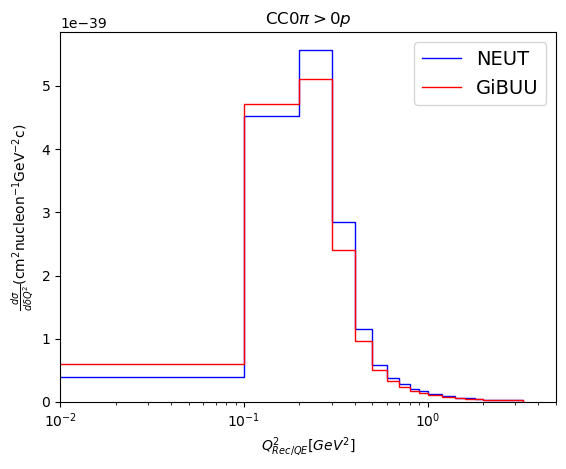

In [38]:
## 12C +1H 
bins_array = np.array([0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.2,1.4,1.6,1.8,2.0,3.3])
constant=weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1)))
### those Q2 within physical range ###
############################## NEUT
test_Q2=output[1][(output[1]<10.0) & (output[1]>0.0)]
mode_cc0pi_neut=mode_arr[mask_cc0pi_all[0]]
enf_arr=truenuE[idx1]*np.ones(len(truenuE[idx1]))
enf_cc0pi_neut=enf_arr[mask_cc0pi_all[0]]

### rewights based on the neutrino energy for 12C
hist1r,bins1=np.histogram(test_Q2[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==1], bins=bins_array)
hist2r,bins1=np.histogram(test_Q2[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==2], bins=bins_array)
hist3r,bins1=np.histogram(test_Q2[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==26], bins=bins_array)

hist4r,bins1=np.histogram(test_Q2[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==11], weights=bspl1(enf_cc0pi_neut[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==11]), bins=bins_array)
hist5r,bins1=np.histogram(test_Q2[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==12], weights=bspl2(enf_cc0pi_neut[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==12]),bins=bins_array)
hist6r,bins1=np.histogram(test_Q2[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==13], weights=bspl3(enf_cc0pi_neut[mode_cc0pi_neut[(output[1]<10.0) & (output[1]>0.0)]==13]),bins=bins_array)
yyr=(hist1r+hist2r+hist3r+hist4r+hist5r+hist6r)*(weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1))))*(len(output[1])/len(test_Q2))## this is to revaluate 12C weights
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
# diff1=np.append(diff,diff[-1])
aa=np.histogram(test_Q2,bins=bins_array,weights=np.ones(len(test_Q2))*len(output[1])/len(test_Q2)*constant,range=(0,2.5))

###################################################################
##########
# plt.stairs((aa[0]+aa_h[0])/diff,aa[1], label="NEUT Reco")
# plt.stairs((yyr+aa_h[0])/diff,bins1,color="red", label="NEUT Reco reweighted for Res")## 12C+1H
plt.stairs((yyr+aa_h[0])/diff,bins1,color="blue", label="NEUT")## 12C+1H

plt.legend(fontsize=14)

################################GiBUU
test_Q2_g=output_g[1][(output_g[1]<10.0) & (output_g[1]>0.0)]
mode_cc0pi_gibuu=mode_arr[mask_cc0pi_all_gibuu[0]]
enf_arr=truenuE[idx1]*np.ones(len(truenuE[idx1]))
enf_cc0pi_gibuu=enf_arr[mask_cc0pi_all_gibuu[0]]

hist1r,bins1=np.histogram(test_Q2_g[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==1], bins=bins_array)
hist2r,bins1=np.histogram(test_Q2_g[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==2], bins=bins_array)
hist3r,bins1=np.histogram(test_Q2_g[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==26], bins=bins_array)
hist4r,bins1=np.histogram(test_Q2_g[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==11], weights=bspl1(enf_cc0pi_neut[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==11]), bins=bins_array)
hist5r,bins1=np.histogram(test_Q2_g[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==12], weights=bspl2(enf_cc0pi_neut[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==12]),bins=bins_array)
hist6r,bins1=np.histogram(test_Q2_g[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==13], weights=bspl3(enf_cc0pi_neut[mode_cc0pi_gibuu[(output_g[1]<10.0) & (output_g[1]>0.0)]==13]),bins=bins_array)
yyr=(hist1r+hist2r+hist3r+hist4r+hist5r+hist6r)*(weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1))))*(len(output_g[1])/len(test_Q2_g))
diff=(bins_array[1:]-bins_array[:-1])
binc=(bins_array[1:]+bins_array[:-1])*0.5
# diff1=np.append(diff,diff[-1])
aa=np.histogram(test_Q2_g,bins=bins_array,weights=np.ones(len(test_Q2_g))*len(output_g[1])/len(test_Q2_g)*constant,range=(0,2.5))
# plt.stairs((aa[0]+aa_h[0])/diff,aa[1], label="GiBUU Reco")
plt.stairs((yyr+aa_h[0])/diff,bins1, color="red",label="GiBUU")
# plt.stairs((yyr+aa_h[0])/diff,bins1, color="blue",label="GiBUU Reco reweighted for Res")

plt.legend(fontsize=14)
# bins_array2 = np.array([0.009375, 0.01875, 0.03125, 0.04375, 0.075, 0.125, 0.175,
#               0.25, 0.35, 0.5, 0.7, 0.9, 1.1, 1.6, 3.0])

# data = np.array([4.70, 6.84, 8.41, 8.92, 9.96, 10.07, 9.85,
#               8.14, 5.97, 3.81, 2.09, 1.18, 0.64, 0.25, 0.02]) * 1e-39

# yerr = np.array([0.60, 0.75, 0.87, 0.93, 0.95, 0.91, 0.87,
#                  0.71, 0.53, 0.30, 0.25, 0.25, 0.25, 0.25, 0.25]) * 1e-39

# xerr = np.array([0.003125, 0.00625, 0.00625, 0.00625, 0.025, 0.025, 0.025,
#                  0.05, 0.05, 0.1, 0.1, 0.1, 0.1, 0.4, 1.0])
# plt.errorbar(bins_array2,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")


plt.legend(fontsize=14)
plt.xlabel(r"$Q_{Rec/QE}^2 [GeV^2]$")
plt.xlim(0,3)
plt.ylabel(r"$\frac{d\sigma}{d\delta Q^2} (\rm cm^{2} nucleon^{-1} GeV^{-2}c)$")
plt.title(r"CC0$\pi>0p$")
plt.legend(fontsize=14)
plt.xlim(0.01,5)
plt.xscale("log")

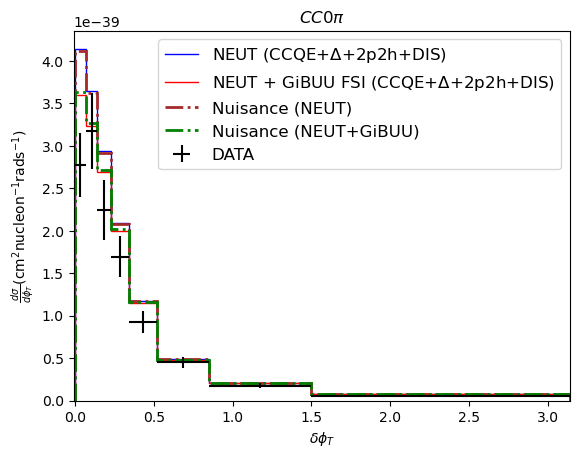

In [49]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy as np
from scipy.interpolate import make_interp_spline
def leading_proton_in_ps(px, py, pz, is_fs_proton, pmin=0.45, pmax=1.0, cosmin=0.4):
    """Pick the highest-momentum final-state proton (no phase-space cut first),
    then flag whether *that* proton is inside the T2K phase space."""
    p = np.sqrt(px**2 + py**2 + pz**2)
    lead = ak.argmax(ak.where(is_fs_proton, p, -1.0), axis=1, keepdims=True)
    p_l, px_l, py_l, pz_l = (ak.firsts(a[lead]) for a in (p, px, py, pz))
    in_ps = ak.any(is_fs_proton, axis=1) & (p_l >= pmin) & (p_l <= pmax) & (pz_l / p_l > cosmin)
    return px_l, py_l, ak.to_numpy(ak.fill_none(in_ps, False))
def dphiT(px_l, py_l, out1, out2):
    """δphiT = angle between -pT(μ) and pl(μ), in radians."""
    cos_a = -(out1*px_l + out2*py_l) / (np.sqrt(out1**2 + out2**2) * np.sqrt(px_l**2 + py_l**2))
    return np.arccos(np.minimum(np.maximum(cos_a, -1.0), 1.0))

# plt.ylabel(r"Xsec_$\Delta$(mode=11,12,13)/Xsec_Tot(mode=11,12,13)")    
def get_leading_proton_dphi(px, py,pz, E, pdg, mode, nue, chase, beam_index,mass_offset=0.025):
    # kinetic energy
    Ef = E - 0.938 - mass_offset
    row_idx = ak.local_index(px, axis=0)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]
    out3 = pz[row_idx, beam_index]

    # proton selection (final state)
    out1T=out1*(ak.ones_like(E))
    out2T=out2*(ak.ones_like(E))
    out3T=out3*(ak.ones_like(E))

    proton_mask = (pdg == 2212) & (chase == 1) &(np.sqrt(px**2+py**2+pz**2)-0.45>=0) & (np.sqrt(px**2+py**2+pz**2)-1.0<=0) & (pz/np.sqrt(px**2+py**2+pz**2)>0.4)
    lepton_mask=  (pdg==13) & (chase==1) & (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (out3T/np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    has_lepton = ak.to_numpy(ak.sum(lepton_mask, axis=1) > 0)
    px_l, py_l, lead_ok = leading_proton_in_ps(px, py, pz, (pdg == 2212) & (chase == 1))
    sel = lead_ok & has_lepton
    return dphiT(px_l, py_l, out1, out2)[sel], mode[sel], nue[sel],sel

def get_leading_proton_dphi_gibuu(px, py,pz, px_all, py_all, pz_all, E, pdg, mode, nue, charge,pdg_all,charge_all, mass_offset=0.0, beam_index=0):
    # kinetic energy
    Ef = E - 0.938 - mass_offset
    out1=px_all[:, beam_index]
    out2=py_all[:, beam_index]
    out3=pz_all[:, beam_index]
    out1T=out1*(ak.ones_like(px_all))
    out2T=out2*(ak.ones_like(px_all))
    out3T=out3*(ak.ones_like(px_all))
    
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (np.sqrt(px**2+py**2+pz**2)-0.45>=0) & (np.sqrt(px**2+py**2+pz**2)-1.0<=0) & (pz/np.sqrt(px**2+py**2+pz**2)>0.4)
    lepton_mask = (pdg_all==902)& (charge_all ==-1)& (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (out3T/np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    
    has_lepton = ak.to_numpy(ak.sum(lepton_mask, axis=1) > 0)
    px_l, py_l, lead_ok = leading_proton_in_ps(px, py, pz, (pdg == 1) & (charge == 1))
    sel = lead_ok & has_lepton
    return dphiT(px_l, py_l, out1, out2)[sel], mode[sel], nue[sel],sel    



weightp=np.ones(len(weight))
weightp[mode==11]=bspl1(truenuE[mode==11])
weightp[mode==12]=bspl2(truenuE[mode==12])
weightp[mode==13]=bspl3(truenuE[mode==13])

weightp_gibuu=np.ones(len(weight))
weightp_gibuu[mode==11]=bspl1(truenuE[mode==11])
weightp_gibuu[(mode==12)|(mode==13)]=bspl4(truenuE[(mode==12)|(mode==13)])


constant=((len(weight[idx])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]
# constant=weight[idx1][0]

######################## hydrogen contribution
binsdpt=np.array([1e-7,0.067,0.14,0.225,0.34,0.52,0.85,1.5,3.1416])
diff=binsdpt[1:]-binsdpt[:-1]
diff=binsdpt[1:]-binsdpt[:-1]
binc=0.5*(binsdpt[1:]+binsdpt[:-1])
mode_h=mode[targetA==1]
pdg_h=pdg[targetA==1]
Q2_h=Q2[targetA==1]
chase_h=chase[targetA==1]
px_h=px[targetA==1]
py_h=py[targetA==1]
pz_h=pz[targetA==1]
truenuE_h=truenuE[targetA==1]
E_h=E[targetA==1]
flesp_index_h=flesp_index[targetA==1]
mass_offset=0.0

mask_on_h=cc0pi_masks(mode_h,pdg_h,Q2_h,chase_h,px_h,py_h,pz_h,E_h,mass_offset)[0]
dphif_neut_cc0pi_h,mode_neut_cc0pi,enf_neut_cc0pi_h,sel_neut_cc0pi_h = get_leading_proton_dphi(
    px_h[mask_on_h],
    py_h[mask_on_h],
    pz_h[mask_on_h],    
    E_h[mask_on_h],
    pdg_h[mask_on_h],
    mode_h[mask_on_h],
    truenuE_h[mask_on_h],   # matches your original px[:,2]
    chase_h[mask_on_h],
    beam_index=flesp_index_h[mask_on_h],
    mass_offset=0.0
)
# histf1_h,binf1=np.histogram(dphif_neut_cc0pi_h,bins=binsdpt)

histf1_h,binf1=np.histogram(dphif_neut_cc0pi_h,weights=weightp[targetA==1][mask_on_h][sel_neut_cc0pi_h]*constant,bins=binsdpt)
# histf1_h=histf1_h*weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1))) 
############################    
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
Q2_neut  = Q2[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]
mass_offset=0.025
mask_cc0pi=cc0pi_masks(mode_neut,pdg_neut,Q2_neut,chase_neut,px_neut,py_neut,pz_neut,E_neut,mass_offset)[0]
# CC0π
dphif_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi,sel_neut_cc0pi = get_leading_proton_dphi(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],
    pz_neut[mask_cc0pi],    
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    beam_index=flesp_index_neut[mask_cc0pi],
    mass_offset=0.025
)
# histf1,binf1=np.histogram(dphif_neut_cc0pi,bins=binsdpt)

histf1,binf1=np.histogram(dphif_neut_cc0pi,weights=weightp[idx1][mask_cc0pi][sel_neut_cc0pi]*constant,bins=binsdpt)
plt.stairs((histf1+histf1_h)/diff,binsdpt,color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")

pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
px_arr3 = px_gibuu_w_med[idx2][:,2:]
py_arr3 = py_gibuu_w_med[idx2][:,2:]
pz_arr3 = pz_gibuu_w_med[idx2][:,2:]
E_arr3   = E_gibuu_w_med[idx2][:,2:]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
px_arr3l = px_gibuu_w_med[idx2][:,0]
py_arr3l = py_gibuu_w_med[idx2][:,0]
pz_arr3l = pz_gibuu_w_med[idx2][:,0]
E_arr3l   = E_gibuu_w_med[idx2][:,0] 
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
mass_offset=0.0
mask_cc0pi_gibuu=cc0pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,mass_offset,px_arr3l,py_arr3l,pz_arr3l,E_arr3l)[0]

dphif_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi,sel_gibuu_cc0pi = get_leading_proton_dphi_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],  
    pz_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],    
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    pz_gibuu_w_med[idx2][mask_cc0pi_gibuu],  
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    charge_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
# histf,binf=np.histogram(dphif_gibuu_w_med_cc0pi,bins=binsdpt)
histf,binf=np.histogram(dphif_gibuu_w_med_cc0pi,weights=weightp_gibuu[idx1][mask_cc0pi_gibuu][sel_gibuu_cc0pi]*constant,bins=binsdpt)
plt.stairs((histf+histf1_h)/diff,binsdpt,color="red", label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")
plt.legend(fontsize=12,framealpha=0.0)
# plt.xlabel(r"$\delta p_T(GeV)$",fontsize=14)
data=[2.779653e-39,3.173144e-39,2.241335e-39,1.697797e-39,9.285808e-40,4.532947e-40,1.78237e-40,5.445145e-41]
xerr=[0.03350,0.03650,0.04250,0.05750,0.0900,0.1650,0.3250,0.8208]
yerr=[3.782e-40,4.490e-40,3.519e-40,2.436e-40,1.309e-40,6.584e-41,2.744e-41,7.951e-42]
# plt.step(x4, np.append(z4*w4[0]*800000/len(w4)/diff,(z4*w4[0]*800000/len(w4)/diff)[-1]),where="post", label="NEUT EQS0")
plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_phi.root")

plt.stairs(file_test['T2K_CC0pinp_STV_XSec_1Ddphit_nu_MC'].values(),file_test['T2K_CC0pinp_STV_XSec_1Ddphit_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test2=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_phi_gibuu.root")

plt.stairs(file_test2['T2K_CC0pinp_STV_XSec_1Ddphit_nu_MC'].values(),file_test2['T2K_CC0pinp_STV_XSec_1Ddphit_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")

plt.ylabel(r"$\frac{d\sigma}{d\phi_T} (\rm cm^{2} nucleon^{-1} rads^{-1})$")
plt.xlabel(r"$\delta \phi_T$")
plt.legend(fontsize=12)
plt.title(r"$CC0\pi$")
plt.xlim(-0.01,3.14)
plt.savefig("CC0pi_delta_phit.png")
# print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))        

In [50]:
file_test['T2K_CC0pinp_STV_XSec_1Ddphit_nu_MC'].values()/((histf1+histf1_h)/diff)

<Array [0.993, 0.994, 0.993, ..., 0.996, 0.996, 0.994] type='8 * float64'>

In [51]:
991853-(len(weight[idx])+len(weight[targetA==1]))

0

In [52]:
sumw=np.ones(len(dphif_neut_cc0pi))
sumw[mode_neut_cc0pi==11]=bspl1(enf_neut_cc0pi[mode_neut_cc0pi==11])
sumw[mode_neut_cc0pi==12]=bspl2(enf_neut_cc0pi[mode_neut_cc0pi==12])
sumw[mode_neut_cc0pi==13]=bspl3(enf_neut_cc0pi[mode_neut_cc0pi==13])
sumw=np.sum(sumw)
1/sumw

np.float64(3.761653690000178e-06)

In [53]:
dphif_neut_cc0pi

<Array [0.243, 0.204, 0.0693, ..., 0.595, 2.53, 1.4] type='268932 * ?float64'>

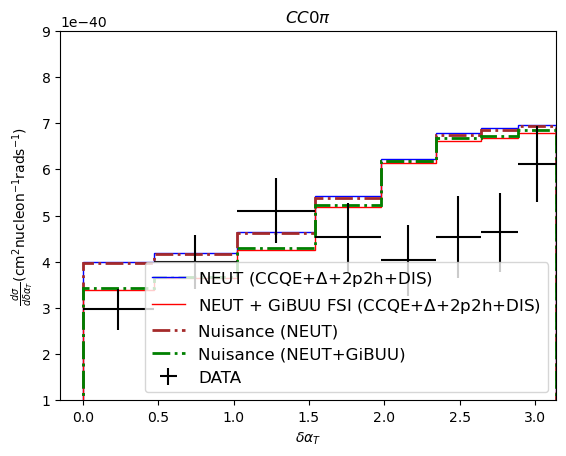

In [54]:
def leading_proton_in_ps(px, py, pz, is_fs_proton, pmin=0.45, pmax=1.0, cosmin=0.4):
    """Pick the highest-momentum final-state proton (no phase-space cut first),
    then flag whether *that* proton is inside the T2K phase space."""
    p = np.sqrt(px**2 + py**2 + pz**2)
    lead = ak.argmax(ak.where(is_fs_proton, p, -1.0), axis=1, keepdims=True)
    p_l, px_l, py_l, pz_l = (ak.firsts(a[lead]) for a in (p, px, py, pz))
    in_ps = ak.any(is_fs_proton, axis=1) & (p_l >= pmin) & (p_l <= pmax) & (pz_l / p_l > cosmin)
    return px_l, py_l, ak.to_numpy(ak.fill_none(in_ps, False))
def dalphaT(px_l, py_l, out1, out2):
    """δαT = angle between -pT(μ) and δpT, in radians."""
    dptx, dpty = px_l + out1, py_l + out2
    cos_a = -(out1*dptx + out2*dpty) / (np.sqrt(out1**2 + out2**2) * np.sqrt(dptx**2 + dpty**2))
    return np.arccos(np.minimum(np.maximum(cos_a, -1.0), 1.0))
def get_leading_proton_dalpha(px, py,pz, E, pdg, mode, nue, chase, beam_index,mass_offset=0.025):
    # kinetic energy
    Ef = E - 0.938 - mass_offset
    row_idx = ak.local_index(px, axis=0)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]
    out3 = pz[row_idx, beam_index]

    # proton selection (final state)
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))
    out1T=out1*(ak.ones_like(E))
    out2T=out2*(ak.ones_like(E))
    out3T=out3*(ak.ones_like(E))

    
    proton_mask = (pdg == 2212) & (chase == 1) & (np.sqrt(px**2+py**2+pz**2)-0.45>=0) & (np.sqrt(px**2+py**2+pz**2)-1.0<=0) & (pz/np.sqrt(px**2+py**2+pz**2)>0.4)
    lepton_mask=  (pdg==13) & (chase==1) & (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (out3T/np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    has_lepton = ak.to_numpy(ak.sum(lepton_mask, axis=1) > 0)
    px_l, py_l, lead_ok = leading_proton_in_ps(px, py, pz, (pdg == 2212) & (chase == 1))
    sel = lead_ok & has_lepton
    return dalphaT(px_l, py_l, out1, out2)[sel], mode[sel], nue[sel],sel

def get_leading_proton_dalpha_gibuu(px, py,pz, px_all, py_all, pz_all, E, pdg, mode, nue, charge,pdg_all,charge_all, mass_offset=0.0, beam_index=0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    out1=px_all[:, beam_index]
    out2=py_all[:, beam_index]
    out3=pz_all[:, beam_index]
    out1T=out1*(ak.ones_like(px_all))
    out2T=out2*(ak.ones_like(px_all))
    out3T=out3*(ak.ones_like(px_all))
    
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (np.sqrt(px**2+py**2+pz**2)-0.45>=0) & (np.sqrt(px**2+py**2+pz**2)-1.0<=0) & (pz/np.sqrt(px**2+py**2+pz**2)>0.4)
    lepton_mask = (pdg_all==902)& (charge_all ==-1)& (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (out3T/np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    
    has_lepton = ak.to_numpy(ak.sum(lepton_mask, axis=1) > 0)
    px_l, py_l, lead_ok = leading_proton_in_ps(px, py, pz, (pdg == 1) & (charge == 1))
    sel = lead_ok & has_lepton
    return dalphaT(px_l, py_l, out1, out2)[sel], mode[sel], nue[sel],sel
######## on hydrogen############
######################## hydrogen contribution
weightp=np.ones(len(weight))
weightp[mode==11]=bspl1(truenuE[mode==11])
weightp[mode==12]=bspl2(truenuE[mode==12])
weightp[mode==13]=bspl3(truenuE[mode==13])

weightp_gibuu=np.ones(len(weight))
weightp_gibuu[mode==11]=bspl1(truenuE[mode==11])
weightp_gibuu[(mode==12)|(mode==13)]=bspl4(truenuE[(mode==12)|(mode==13)])


constant=((len(weight[idx])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]
binsdpt=np.array([1e-7,0.47,1.02,1.54,1.98,2.34,2.64,2.89,3.1416])
diff=binsdpt[1:]-binsdpt[:-1]
binc=0.5*(binsdpt[1:]+binsdpt[:-1])



mode_h=mode[targetA==1]
pdg_h=pdg[targetA==1]
Q2_h=Q2[targetA==1]
chase_h=chase[targetA==1]
px_h=px[targetA==1]
py_h=py[targetA==1]
pz_h=pz[targetA==1]
truenuE_h=truenuE[targetA==1]
E_h=E[targetA==1]
flesp_index_h=flesp_index[targetA==1]
mass_offset=0.0

mask_on_h=cc0pi_masks(mode_h,pdg_h,Q2_h,chase_h,px_h,py_h,pz_h,E_h,mass_offset)[0]
dalphaf_neut_cc0pi_h,mode_neut_cc0pi,enf_neut_cc0pi_h,sel_neut_cc0pi_h = get_leading_proton_dalpha(
    px_h[mask_on_h],
    py_h[mask_on_h],
    pz_h[mask_on_h],    
    E_h[mask_on_h],
    pdg_h[mask_on_h],
    mode_h[mask_on_h],
    truenuE_h[mask_on_h],   # matches your original px[:,2]
    chase_h[mask_on_h],
    beam_index=flesp_index_h[mask_on_h],
    mass_offset=0.0
)
histf1_h,binf1=np.histogram(dalphaf_neut_cc0pi_h,weights=weightp[targetA==1][mask_on_h][sel_neut_cc0pi_h]*constant,bins=binsdpt)
# histf1_h=histf1_h*weight[idx1][0]

##################################
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
Q2_neut  = Q2[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]
mass_offset=0.025
mask_cc0pi=cc0pi_masks(mode_neut,pdg_neut,Q2_neut,chase_neut,px_neut,py_neut,pz_neut,E_neut,mass_offset)[0]
# CC0π
dalphaf_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi,sel_neut_cc0pi = get_leading_proton_dalpha(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],
    pz_neut[mask_cc0pi],    
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    beam_index=flesp_index_neut[mask_cc0pi],
    mass_offset=0.025
)

histf1,binf1=np.histogram(dalphaf_neut_cc0pi,weights=weightp[idx1][mask_cc0pi][sel_neut_cc0pi]*constant,bins=binsdpt)
plt.stairs((histf1+histf1_h)/diff,binsdpt,color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")

np.histogram(dphif_neut_cc0pi,bins=binsdpt)

pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
px_arr3 = px_gibuu_w_med[idx2][:,2:]
py_arr3 = py_gibuu_w_med[idx2][:,2:]
pz_arr3 = pz_gibuu_w_med[idx2][:,2:]
E_arr3   = E_gibuu_w_med[idx2][:,2:]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
px_arr3l = px_gibuu_w_med[idx2][:,0]
py_arr3l = py_gibuu_w_med[idx2][:,0]
pz_arr3l = pz_gibuu_w_med[idx2][:,0]
E_arr3l   = E_gibuu_w_med[idx2][:,0] 
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
mass_offset=0.0
mask_cc0pi_gibuu=cc0pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,mass_offset,px_arr3l,py_arr3l,pz_arr3l,E_arr3l)[0]

dalphaf_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi,sel_gibuu_cc0pi = get_leading_proton_dalpha_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu], 
    pz_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],       
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    pz_gibuu_w_med[idx2][mask_cc0pi_gibuu],  
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    charge_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)

histf,binf=np.histogram(dalphaf_gibuu_w_med_cc0pi,weights=weightp_gibuu[idx1][mask_cc0pi_gibuu][sel_gibuu_cc0pi]*constant,bins=binsdpt)
plt.stairs((histf+histf1_h)/diff,binsdpt,color="red", label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")
plt.legend(fontsize=12,framealpha=0.0)
# plt.xlabel(r"$\delta p_T(GeV)$",fontsize=14)
data=[2.972902e-40,4.002167e-40,5.107919e-40,4.52447e-40,4.030542e-40,4.536319e-40,4.63668e-40,6.114412e-40]
xerr=[0.2350,0.2750,0.2600,0.2200,0.1800,0.1500,0.1250,0.1258]
yerr=[4.474e-41,5.841e-41,7.022e-41,7.372e-41,7.619e-41,8.820e-41,8.484e-41,8.184e-41]
# plt.step(x4, np.append(z4*w4[0]*800000/len(w4)/diff,(z4*w4[0]*800000/len(w4)/diff)[-1]),where="post", label="NEUT EQS0")
plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_alpha.root")

plt.stairs(file_test['T2K_CC0pinp_STV_XSec_1Ddat_nu_MC'].values(),file_test['T2K_CC0pinp_STV_XSec_1Ddat_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_alpha_gibuu.root")

plt.stairs(file_test['T2K_CC0pinp_STV_XSec_1Ddat_nu_MC'].values(),file_test['T2K_CC0pinp_STV_XSec_1Ddat_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")


plt.ylabel(r"$\frac{d\sigma}{d\delta \alpha_T} (\rm cm^{2} nucleon^{-1} rads^{-1})$")
plt.xlabel(r"$\delta \alpha_T$")
plt.legend(fontsize=12)
plt.title(r"$CC0\pi$")
plt.xlim(-0.15,3.14)
plt.ylim(1*10**-40,9*10**-40)
# print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))  
plt.savefig("CC0pi_delta_alphat.png")
  

In [55]:
weightp_gibuu

array([1.00015997, 1.        , 0.98531454, ..., 1.        , 1.        ,
       0.99797777], shape=(1000000,))

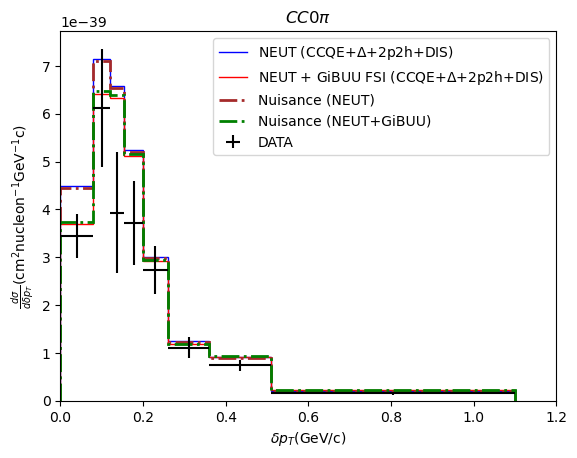

In [56]:
def leading_proton_in_ps(px, py, pz, is_fs_proton, pmin=0.45, pmax=1.0, cosmin=0.4):
    """Pick the highest-momentum final-state proton (no phase-space cut first),
    then flag whether *that* proton is inside the T2K phase space."""
    p = np.sqrt(px**2 + py**2 + pz**2)
    lead = ak.argmax(ak.where(is_fs_proton, p, -1.0), axis=1, keepdims=True)
    p_l, px_l, py_l, pz_l = (ak.firsts(a[lead]) for a in (p, px, py, pz))
    in_ps = ak.any(is_fs_proton, axis=1) & (p_l >= pmin) & (p_l <= pmax) & (pz_l / p_l > cosmin)
    return px_l, py_l, ak.to_numpy(ak.fill_none(in_ps, False))
def get_leading_proton_dpt(px, py,pz, E, pdg, mode, nue, chase, beam_index,mass_offset=0.025):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    row_idx = ak.local_index(px, axis=0)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]
    out3 = pz[row_idx, beam_index]

    # proton selection (final state)
    # nue=nue*(ak.ones_like(E))
    # mode=mode*(ak.ones_like(E))
    out1T=out1*(ak.ones_like(E))
    out2T=out2*(ak.ones_like(E))
    out3T=out3*(ak.ones_like(E))

    
    proton_mask = (pdg == 2212) & (chase == 1) & (np.sqrt(px**2+py**2+pz**2)-0.45>=0) & (np.sqrt(px**2+py**2+pz**2)-1.0<=0) & (pz/np.sqrt(px**2+py**2+pz**2)>0.4)
    lepton_mask=  (pdg==13) & (chase==1) & (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (out3T/np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    is_fs_proton = (pdg == 2212) & (chase == 1)     # NEUT
    # is_fs_proton = (pdg == 1) & (charge == 1)     # GiBUU

    has_lepton = ak.to_numpy(ak.sum(lepton_mask, axis=1) > 0)
    px_l, py_l, lead_ok = leading_proton_in_ps(px, py, pz, is_fs_proton)
    sel = lead_ok & has_lepton

    dpt = np.sqrt((px_l + out1)**2 + (py_l + out2)**2)
    return dpt[sel], mode[sel], nue[sel],sel

def get_leading_proton_dpt_gibuu(px, py,pz, px_all, py_all, pz_all, E, pdg, mode, nue, charge,pdg_all,charge_all, mass_offset=0.0, beam_index=0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    out1=px_all[:, beam_index]
    out2=py_all[:, beam_index]
    out3=pz_all[:, beam_index]
    out1T=out1*(ak.ones_like(px_all))
    out2T=out2*(ak.ones_like(px_all))
    out3T=out3*(ak.ones_like(px_all))
    
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (np.sqrt(px**2+py**2+pz**2)-0.45>=0) & (np.sqrt(px**2+py**2+pz**2)-1.0<=0) & (pz/np.sqrt(px**2+py**2+pz**2)>0.4)
    lepton_mask = (pdg_all==902)& (charge_all ==-1)& (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (out3T/np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) > -0.6)
    is_fs_proton = (pdg == 1) & (charge == 1)

    has_lepton = ak.to_numpy(ak.sum(lepton_mask, axis=1) > 0)
    px_l, py_l, lead_ok = leading_proton_in_ps(px, py, pz, is_fs_proton)
    sel = lead_ok & has_lepton

    dpt = np.sqrt((px_l + out1)**2 + (py_l + out2)**2)
    return dpt[sel], mode[sel], nue[sel],sel
############## on hydrogen ##########

weightp=np.ones(len(weight))
weightp[mode==11]=bspl1(truenuE[mode==11])
weightp[mode==12]=bspl2(truenuE[mode==12])
weightp[mode==13]=bspl3(truenuE[mode==13])

weightp_gibuu=np.ones(len(weight))
weightp_gibuu[mode==11]=bspl1(truenuE[mode==11])
weightp_gibuu[(mode==12)|(mode==13)]=bspl4(truenuE[(mode==12)|(mode==13)])


constant=((len(weight[idx])+len(weight[targetA==1]))/1e6)**(-1)*weight[idx1][0]
binsdpt=np.array([1e-7,0.08,0.12,0.155,0.20,0.26,0.36,0.51,1.1])
diff=binsdpt[1:]-binsdpt[:-1]

mode_h=mode[(targetA==1)]
pdg_h=pdg[targetA==1]
Q2_h=Q2[targetA==1]
chase_h=chase[targetA==1]
px_h=px[targetA==1]
py_h=py[targetA==1]
pz_h=pz[targetA==1]
truenuE_h=truenuE[targetA==1]
E_h=E[targetA==1]
flesp_index_h=flesp_index[targetA==1]
mass_offset=0.0

mask_on_h=cc0pi_masks(mode_h,pdg_h,Q2_h,chase_h,px_h,py_h,pz_h,E_h,mass_offset)[0]
dptf_neut_cc0pi_h,mode_neut_cc0pi_h,enf_neut_cc0pi_h ,sel_neut_cc0pi_h= get_leading_proton_dpt(
    px_h[mask_on_h],
    py_h[mask_on_h],
    pz_h[mask_on_h],    
    E_h[mask_on_h],
    pdg_h[mask_on_h],
    mode_h[mask_on_h],
    truenuE_h[mask_on_h],   # matches your original px[:,2]
    chase_h[mask_on_h],
    beam_index=flesp_index_h[mask_on_h],
    mass_offset=0.0
)
histf1_h,binf1=np.histogram(dptf_neut_cc0pi_h,weights=weightp[targetA==1][mask_on_h][sel_neut_cc0pi_h]*constant,bins=binsdpt)

###########################
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
Q2_neut  = Q2[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]
mass_offset=0.025
mask_cc0pi=cc0pi_masks(mode_neut,pdg_neut,Q2_neut,chase_neut,px_neut,py_neut,pz_neut,E_neut,mass_offset)[0]
# CC0π
dptf_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi,sel_neut_cc0pi = get_leading_proton_dpt(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],
    pz_neut[mask_cc0pi],    
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    beam_index=flesp_index_neut[mask_cc0pi],
    mass_offset=0.025
)

histf1,binf1=np.histogram(dptf_neut_cc0pi,weights=weightp[idx1][mask_cc0pi][sel_neut_cc0pi]*constant,bins=binsdpt)
plt.stairs((histf1+histf1_h)/diff,binsdpt,color="blue", label=r"NEUT (CCQE+$\Delta$+2p2h+DIS)")

np.histogram(dphif_neut_cc0pi,bins=binsdpt)

pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
px_arr3 = px_gibuu_w_med[idx2][:,2:]
py_arr3 = py_gibuu_w_med[idx2][:,2:]
pz_arr3 = pz_gibuu_w_med[idx2][:,2:]
E_arr3   = E_gibuu_w_med[idx2][:,2:]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
px_arr3l = px_gibuu_w_med[idx2][:,0]
py_arr3l = py_gibuu_w_med[idx2][:,0]
pz_arr3l = pz_gibuu_w_med[idx2][:,0]
E_arr3l   = E_gibuu_w_med[idx2][:,0] 
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
mass_offset=0.0
mask_cc0pi_gibuu=cc0pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,mass_offset,px_arr3l,py_arr3l,pz_arr3l,E_arr3l)[0]

dptf_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi,sel_gibuu_cc0pi = get_leading_proton_dpt_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],   
    pz_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],       
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    pz_gibuu_w_med[idx2][mask_cc0pi_gibuu],  
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    charge_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
histf,binf=np.histogram(dptf_gibuu_w_med_cc0pi,weights=weightp_gibuu[idx1][mask_cc0pi_gibuu][sel_gibuu_cc0pi]*constant,bins=binsdpt)
plt.stairs((histf+histf1_h)/diff,binsdpt,color="red", label=r"NEUT + GiBUU FSI (CCQE+$\Delta$+2p2h+DIS)")
plt.legend(fontsize=12,framealpha=0.0)
binsdpt=np.array([1e-7,0.08,0.12,0.155,0.20,0.26,0.36,0.51,1.1])
binc=0.5*(binsdpt[1:]+binsdpt[:-1])
# plt.step(x, np.append(z4*w4[0]*800000/len(w4)/diff,(z4*w4[0]*800000/len(w4)/diff)[-1]),where="post", label="NEUT EQS0")
data=[3.4453411e-39, 6.126043e-39,3.930214e-39,3.709638e-39,2.728855e-39,1.103397e-39,7.39485e-40,1.584798e-40]
# xerr=[0.04,0.02,0.01750,0.02250,0.03,0.05,0.0705,0.2950]
xerr=diff/2
yerr=[4.568e-40,1.234e-39,1.261e-39,8.800e-40,5.018e-40,2.20e-40,1.207e-40,3.313e-41]
plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_pt.root")

plt.stairs(file_test['T2K_CC0pinp_STV_XSec_1Ddpt_nu_MC'].values(),file_test['T2K_CC0pinp_STV_XSec_1Ddpt_nu_MC'].axis().edges(),color="brown",ls="-.",lw=2,label="Nuisance (NEUT)")

file_test=uproot.open("/data/neutrinos/scratch/pingal/nuisance/build/app/test_pt_gibuu.root")

plt.stairs(file_test['T2K_CC0pinp_STV_XSec_1Ddpt_nu_MC'].values(),file_test['T2K_CC0pinp_STV_XSec_1Ddpt_nu_MC'].axis().edges(),color="green",ls="-.",lw=2,label="Nuisance (NEUT+GiBUU)")

plt.ylabel(r"$\frac{d\sigma}{d\delta p_T} (\rm cm^{2} nucleon^{-1} GeV^{-1}c)$")
plt.xlabel(r"$\delta p_T (\rm GeV/c)$")
plt.legend(fontsize=10)
plt.title(r"$CC0\pi$")
plt.xlim(0.0,1.2)
# print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))  
plt.savefig("CC0pi_delta_pt.png")


[] []
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, ..., 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 3] [1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..., 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1]


(0.0, 1.2)

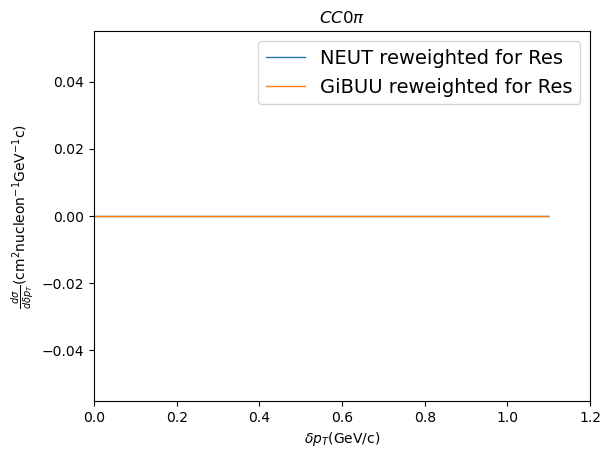

In [57]:
def get_leading_proton_dpt(px, py, E, pdg, mode, nue, chase, beam_index,mass_offset=0.025):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    row_idx = ak.local_index(px, axis=0)

    out1 = px[row_idx, beam_index]
    out2 = py[row_idx, beam_index]
    out3 = pz[row_idx, beam_index]

    # proton selection (final state)
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))
    out1T=out1*(ak.ones_like(E))
    out2T=out2*(ak.ones_like(E))
    out3T=out3*(ak.ones_like(E))

    
    proton_mask = (pdg == 2212) & (chase == 1) & (Ef -( np.sqrt(0.45**2+0.938**2)-0.938-mass_offset)>0) & (Ef -( np.sqrt(1.0**2+0.938**2-mass_offset)-0.938)<0)
    lepton_mask=  (pdg==13) & (chase==1) & (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (np.arctan(np.sqrt(out1T*out1T+out2T*out2T)/out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    print(n_proton,n_lepton)
    mask_event=(n_proton>0)&(n_lepton>0)
    proton_mask=proton_mask[mask_event]
                            
    dptx = px + out1T
    dpty = py + out2T

    # apply mask
    dptx_p = dptx[mask_event][proton_mask]
    dpty_p = dpty[mask_event][proton_mask]
    Ef_p   = Ef[mask_event][proton_mask]
    mode_p=mode[mask_event][proton_mask]
    nue_p=nue[mask_event][proton_mask]

    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    dptx_p = dptx_p[valid]
    dpty_p = dpty_p[valid]
    Ef_p   = Ef_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]

    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dptx_sorted = dptx_p[sorted_idx]
    dpty_sorted = dpty_p[sorted_idx]
    dptx_lead = ak.firsts(dptx_sorted)
    dpty_lead = ak.firsts(dpty_sorted)

    return np.sqrt(dptx_lead**2 + dpty_lead**2),ak.firsts(mode_p),ak.firsts(nue_p)

def get_leading_proton_dpt_gibuu(px, py, px_all, py_all, pz_all, E, pdg, mode, nue, charge,pdg_all,charge_all, mass_offset=0.0, beam_index=0):

    # kinetic energy
    Ef = E - 0.938 - mass_offset
    out1=px_all[:, beam_index]
    out2=py_all[:, beam_index]
    out3=pz_all[:, beam_index]
    out1T=out1*(ak.ones_like(px_all))
    out2T=out2*(ak.ones_like(px_all))
    out3T=out3*(ak.ones_like(px_all))
    
    # proton selection (final state)
    proton_mask = (pdg == 1) & (charge ==1) & (Ef -( np.sqrt(0.45**2+0.938**2)-0.938)>0) & (Ef -( np.sqrt(1.0**2+0.938**2)-0.938)<0)
    lepton_mask = (pdg_all==902)& (charge_all ==-1)& (np.sqrt(out1T*out1T+out2T*out2T+out3T*out3T) >0.25) & (np.arctan(np.sqrt(out1T*out1T+out2T*out2T)/out3T) > -0.6)
    n_proton=ak.sum(proton_mask, axis=1)
    n_lepton=ak.sum(lepton_mask, axis=1)
    
    mask_event=(n_proton>0) & (n_lepton>0)
    proton_mask=proton_mask[mask_event]
    nue=nue*(ak.ones_like(E))
    mode=mode*(ak.ones_like(E))

    
    # ΔpT definition (your convention)
    dptx = px + px_all[:, beam_index]
    dpty = py + py_all[:, beam_index]

    # apply mask
    dptx_p = dptx[mask_event][proton_mask]
    dpty_p = dpty[mask_event][proton_mask]
    Ef_p   = Ef[mask_event][proton_mask]
    mode_p=mode[mask_event][proton_mask]
    nue_p=nue[mask_event][proton_mask]
    # keep only events with ≥1 proton
    valid = ak.num(Ef_p, axis=1) > 0
    dptx_p = dptx_p[valid]
    dpty_p = dpty_p[valid]
    Ef_p   = Ef_p[valid]
    mode_p = mode_p[valid]
    nue_p = nue_p[valid]
    # leading proton index per event
    sorted_idx = ak.argsort(Ef_p, axis=1, ascending=False)

    dptx_sorted = dptx_p[sorted_idx]
    dpty_sorted = dpty_p[sorted_idx]

    dptx_lead = ak.firsts(dptx_sorted)
    dpty_lead = ak.firsts(dpty_sorted)

    return np.sqrt(dptx_lead**2 + dpty_lead**2),ak.firsts(mode_p),ak.firsts(nue_p)
############## on hydrogen ##########

constant=(weight[idx1][0]*(1000000/(np.size(weight[idx1])+np.sum(targetA==1)))) 
binsdpt=np.array([1e-7,0.08,0.12,0.155,0.20,0.26,0.36,0.51,1.1])
diff=binsdpt[1:]-binsdpt[:-1]

mode_h=mode[(targetA==1)& (mode==1)]
pdg_h=pdg[targetA==1& (mode==1)]
Q2_h=Q2[targetA==1& (mode==1)]
chase_h=chase[targetA==1& (mode==1)]
px_h=px[targetA==1& (mode==1)]
py_h=py[targetA==1& (mode==1)]
pz_h=pz[targetA==1& (mode==1)]
truenuE_h=truenuE[targetA==1& (mode==1)]
E_h=E[targetA==1& (mode==1)]
flesp_index_h=flesp_index[targetA==1& (mode==1)]
mass_offset=0.0

mask_on_h=cc0pi_masks(mode_h,pdg_h,Q2_h,chase_h,px_h,py_h,pz_h,E_h,mass_offset)[0]
dptf_neut_cc0pi_h,mode_neut_cc0pi,enf_neut_cc0pi = get_leading_proton_dpt(
    px_h[mask_on_h],
    py_h[mask_on_h],
    E_h[mask_on_h],
    pdg_h[mask_on_h],
    mode_h[mask_on_h],
    truenuE_h[mask_on_h],   # matches your original px[:,2]
    chase_h[mask_on_h],
    beam_index=flesp_index_h[mask_on_h],
    mass_offset=0.0
)
histf1_h,binf1=np.histogram(dptf_neut_cc0pi_h,bins=binsdpt)
histf1_h=histf1_h*weight[idx1][0]

###########################
px_neut = px[idx1]
py_neut = py[idx1]
pz_neut = pz[idx1]
E_neut  = E[idx1]
Q2_neut  = Q2[idx1]
mode_neut=mode[idx1]
truenuE_nuet=truenuE[idx1]
pdg_neut   = pdg[idx1]
chase_neut = chase[idx1]
flesp_index_neut=flesp_index[idx1]
mass_offset=0.025
mask_cc0pi=cc0pi_masks(mode_neut,pdg_neut,Q2_neut,chase_neut,px_neut,py_neut,pz_neut,E_neut,mass_offset)[0]
# CC0π
dptf_neut_cc0pi,mode_neut_cc0pi,enf_neut_cc0pi = get_leading_proton_dpt(
    px_neut[mask_cc0pi],
    py_neut[mask_cc0pi],
    E_neut[mask_cc0pi],
    pdg_neut[mask_cc0pi],
    mode_neut[mask_cc0pi],
    truenuE_nuet[mask_cc0pi],   # matches your original px[:,2]
    chase_neut[mask_cc0pi],
    beam_index=flesp_index_neut[mask_cc0pi],
    mass_offset=0.025
)

histf1,binf1=np.histogram(dptf_neut_cc0pi,bins=binsdpt)
plt.stairs((histf1_h)/diff,binsdpt, label="NEUT reweighted for Res")

np.histogram(dphif_neut_cc0pi,bins=binsdpt)

pdg_arr3   = ID_gibuu_w_med[idx2][:,2:]
charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
px_arr3 = px_gibuu_w_med[idx2][:,2:]
py_arr3 = py_gibuu_w_med[idx2][:,2:]
pz_arr3 = pz_gibuu_w_med[idx2][:,2:]
E_arr3   = E_gibuu_w_med[idx2][:,2:]
p_arr3= np.sqrt(px_arr3**2+py_arr3**2+pz_arr3**2)
px_arr3l = px_gibuu_w_med[idx2][:,0]
py_arr3l = py_gibuu_w_med[idx2][:,0]
pz_arr3l = pz_gibuu_w_med[idx2][:,0]
E_arr3l   = E_gibuu_w_med[idx2][:,0] 
mode_arr3=mode[idx1]*ak.ones_like(pdg_arr3)
enf_arr3=truenuE[idx1]*ak.ones_like(pdg_arr3)
mass_offset=0.0
mask_cc0pi_gibuu=cc0pi_masks_gibuu(mode_arr3,pdg_arr3,Q2_arr,charge_arr3,px_arr3,py_arr3,pz_arr3,E_arr3,mass_offset,px_arr3l,py_arr3l,pz_arr3l,E_arr3l)[0]

dptf_gibuu_w_med_cc0pi,mode_gibuu_cc0pi,enf_gibuu_cc0pi = get_leading_proton_dpt_gibuu(
    px_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],   
    px_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    py_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    pz_gibuu_w_med[idx2][mask_cc0pi_gibuu],  
    E_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    mode_neut[mask_cc0pi_gibuu],
    truenuE_nuet[mask_cc0pi_gibuu],    
    charge_gibuu_w_med[idx2][:,2:][mask_cc0pi_gibuu],
    ID_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    charge_gibuu_w_med[idx2][mask_cc0pi_gibuu],
    mass_offset=0.0,
    beam_index=0
)
# hist1g,bin1=np.histogram(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==1],bins=binsdpt)
# hist2g,bin1=np.histogram(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==2],bins=binsdpt,range=(0,0.9))
# hist3g,bin1=np.histogram(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==26],bins=binsdpt,range=(0,0.9))

# hist4g,bin1=np.histogram(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==11], weights=bspl1(enf_gibuu_cc0pi[mode_gibuu_cc0pi==11]),bins=binsdpt,range=(0,0.9))
# hist5g,bin1=np.histogram(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==12],weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==12]),bins=binsdpt,range=(0,0.9))
# hist6g,bin1=np.histogram(dphif_gibuu_w_med_cc0pi[mode_gibuu_cc0pi==13], weights=bspl4(enf_gibuu_cc0pi[mode_gibuu_cc0pi==13]),bins=binsdpt,range=(0,0.9))
# plt.step(bin1[-1], (hist1+hist2,hist3+hist4+his5+hist6)*constant,where="post")

# plt.step((binsdpt[1:]+binsdpt[:-1])/2,hist1g, label="p(GiBUU FSI Reweighted for Res)", color="pink", where="pre")

histf,binf=np.histogram(dptf_gibuu_w_med_cc0pi,bins=binsdpt)
plt.stairs((histf1_h)/diff,binsdpt, label="GiBUU reweighted for Res")
plt.legend(fontsize=12,framealpha=0.0)
binsdpt=np.array([1e-7,0.08,0.12,0.155,0.20,0.26,0.36,0.51,1.1])
binc=0.5*(binsdpt[1:]+binsdpt[:-1])
# plt.step(x, np.append(z4*w4[0]*800000/len(w4)/diff,(z4*w4[0]*800000/len(w4)/diff)[-1]),where="post", label="NEUT EQS0")
data=[3.4453411e-39, 6.126043e-39,3.930214e-39,3.709638e-39,2.728855e-39,1.103397e-39,7.39485e-40,1.584798e-40]
xerr=[0.04,0.02,0.01750,0.02250,0.03,0.05,0.0705,0.2950]
yerr=[4.568e-40,1.234e-39,1.261e-39,8.800e-40,5.018e-40,2.20e-40,1.207e-40,3.313e-41]
# plt.errorbar(binc,data,xerr=xerr,yerr=yerr, color="black", fmt='none', label="DATA")
plt.ylabel(r"$\frac{d\sigma}{d\delta p_T} (\rm cm^{2} nucleon^{-1} GeV^{-1}c)$")
plt.xlabel(r"$\delta p_T (\rm GeV/c)$")
plt.legend(fontsize=14)
plt.title(r"$CC0\pi$")
plt.xlim(0.0,1.2)
# print(len(dptf_neut),len(dptf_gibuu_wo_med),len(dptf_gibuu_w_med))  
        

In [58]:
pdg_h

<Array [] type='0 * var * int32'>

In [59]:
chase_h

<Array [] type='0 * var * int32'>

In [60]:
np.unique(mode)

<Array [1, 2, 11, 12, 13, 26] type='6 * int32'>